**Topic:** Understanding Artificial Neural Networks and Single-Layer Perceptrons

## Group Members

| Name | Student Number |
|---|---|
| Sukhchain Singh | 9111541 |
| Ubaid Ullah | 9110715 |
| Ved Patel | 9111628 |
| Koushik Balne | 9087547 |

## Workshop Overview

In this workshop, we explore how artificial neurons use inputs,
weights, biases, and activation functions to make predictions.

We follow the provided examples, including the Canada's Wonderland
decision and logic gates. We also compare different movie-going
preferences by changing weights and biases.

For the final challenge, we implement the single-layer prostate
cancer prediction example from the Deep Learning Fundamentals
class notes. We use the supplied weights and biases, explain the
outputs, and visualize how the model responds to different PSA inputs.

## Prostate Cancer Prediction — Single-Layer ANN

We implement the example from the Deep Learning Fundamentals notes.
The model takes PSA as its input and calculates two outputs:
Cancer and Healthy.

Each output uses a weight, a bias, and the sigmoid activation function.
We use the supplied weights rather than training a new model.

This is a classroom demonstration, not a clinical prediction tool.

In [1]:
import torch

# Sample PSA values shown in the class notes.
# Each row represents one example.
psa_inputs = torch.tensor([[2.0], [2.7]], dtype=torch.float64)

# Columns represent Cancer and Healthy.
output_weights = torch.tensor(
    [[2.747, -2.747]], dtype=torch.float64
)
output_biases = torch.tensor(
    [-5.754, 5.754], dtype=torch.float64
)

# Forward pass: weighted input + bias, followed by sigmoid.
linear_scores = psa_inputs @ output_weights + output_biases
probabilities = torch.sigmoid(linear_scores)

for index, psa in enumerate(psa_inputs[:, 0]):
    cancer_probability, healthy_probability = probabilities[index].tolist()

    predicted_class = (
        "Cancer" if cancer_probability > 0.5 else "Healthy"
    )

    print(f"PSA input: {psa.item():.1f}")
    print(f"Cancer output: {cancer_probability:.4f}")
    print(f"Healthy output: {healthy_probability:.4f}")
    print(f"Predicted class: {predicted_class}\n")

PSA input: 2.0
Cancer output: 0.4354
Healthy output: 0.5646
Predicted class: Healthy

PSA input: 2.7
Cancer output: 0.8406
Healthy output: 0.1594
Predicted class: Cancer



### Understanding Our Results

For PSA = 2.0, the model produces a Cancer output of approximately
0.4354 and a Healthy output of 0.5646. Since the Cancer output is
below 0.5, the predicted class is Healthy.

For PSA = 2.7, the Cancer output increases to approximately 0.8406.
Since this is above 0.5, the predicted class is Cancer.

These results use the weights supplied in the class notes. We have
implemented prediction, but we have not trained or evaluated the
model on a patient dataset.

### Small Calculation Difference in the Slides

Using the displayed weights:
-5.754 + (2.747 × 2.0) = -0.260, rather than -0.251.

Therefore, our Cancer output is approximately 0.4354 instead of
0.438. The predicted class remains the same.

The two outputs add up to 1 because their weights and biases are
exact opposites and sigmoid(-z) = 1 - sigmoid(z).
Two sigmoid outputs do not automatically add up to 1 in every ANN.

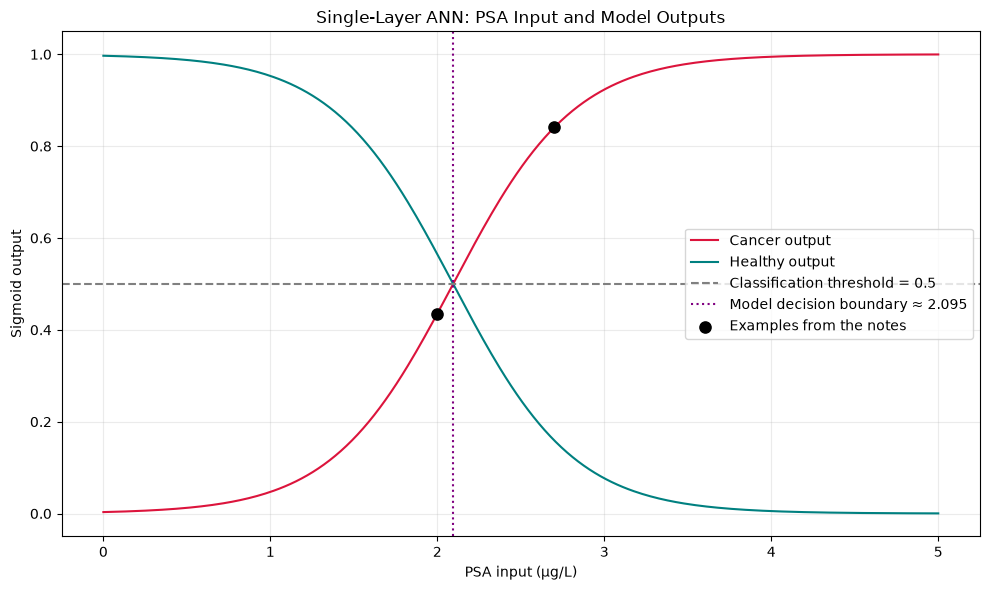

Model decision boundary: 2.0946


In [2]:
import matplotlib.pyplot as plt

# Generate inputs to explore the supplied model.
# These are plotting values, not a patient dataset.
psa_range = torch.linspace(
    0, 5, 300, dtype=torch.float64
).reshape(-1, 1)

with torch.no_grad():
    curve_scores = psa_range @ output_weights + output_biases
    curve_probabilities = torch.sigmoid(curve_scores)

# Cancer output reaches 0.5 when its linear score equals zero.
decision_boundary = (
    -output_biases[0] / output_weights[0, 0]
).item()

plt.figure(figsize=(10, 6))

plt.plot(
    psa_range[:, 0].numpy(),
    curve_probabilities[:, 0].numpy(),
    label="Cancer output",
    color="crimson",
)
plt.plot(
    psa_range[:, 0].numpy(),
    curve_probabilities[:, 1].numpy(),
    label="Healthy output",
    color="teal",
)

plt.axhline(
    0.5, color="gray", linestyle="--",
    label="Classification threshold = 0.5",
)
plt.axvline(
    decision_boundary, color="purple", linestyle=":",
    label=f"Model decision boundary ≈ {decision_boundary:.3f}",
)

plt.scatter(
    psa_inputs[:, 0].numpy(),
    probabilities[:, 0].numpy(),
    color="black", s=65, zorder=5,
    label="Examples from the notes",
)

plt.title("Single-Layer ANN: PSA Input and Model Outputs")
plt.xlabel("PSA input (µg/L)")
plt.ylabel("Sigmoid output")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Model decision boundary: {decision_boundary:.4f}")

### Three Talking Points

1. **How the model makes a prediction**
   The model multiplies PSA by each output's weight, adds its bias,
   and applies sigmoid. We use a threshold of 0.5 on the Cancer
   output to choose a class.

2. **How weights and biases affect the result**
   The positive Cancer weight makes its output increase as PSA
   increases. The negative Healthy weight makes its output decrease.
   The biases shift where the model changes its decision.

3. **What this implementation demonstrates**
   This is a single-layer ANN with one input, two output neurons,
   and no hidden layer. It uses supplied parameters for prediction.
   Without labelled evaluation data, we cannot report accuracy or
   claim that it works reliably on new patients.

### How Is Gradient Descent Related to Backpropagation?

Backpropagation calculates how each trainable weight and bias
contributes to the loss. It uses the chain rule to calculate gradients,
working backwards through the network.

Gradient descent uses those gradients to update the parameters
in the direction that reduces the loss.

In simple words:
- Backpropagation calculates the gradients.
- Gradient descent uses them to change the weights and biases.

In the Wonderland example, loss.backward() calculates the gradients.
The update inside torch.no_grad() applies a gradient descent step.
That example updates the weights only; its bias is a fixed number.

Our prostate cancer implementation only performs a forward pass
with the supplied weights, so it does not perform backpropagation.

## Movie Decision: Comparing Different Preferences

We compare three ways of deciding whether to go to the movies.

The inputs are:
- Weather: 1 = good, 0 = bad.
- Company: 1 = someone joins us, 0 = going alone.
- Proximity: 1 = nearby, 0 = far away.

We use a step activation: output 1 when the weighted score is
greater than zero; otherwise, output 0.

In [1]:
from itertools import product

movie_scenarios = {
    "All three conditions required": ([1.0, 1.0, 1.0], -2.5),
    "Any two conditions required": ([1.0, 1.0, 1.0], -1.5),
    "Company alone is enough": ([1.0, 3.0, 1.0], -2.5),
}

for scenario, (movie_weights, movie_bias) in movie_scenarios.items():
    print(f"\n{scenario}")
    print("Weather Company Nearby | Score | Go?")
    print("-" * 42)

    for movie_inputs in product([0, 1], repeat=3):
        score = sum(
            weight * value
            for weight, value in zip(movie_weights, movie_inputs)
        ) + movie_bias

        decision = int(score > 0)
        weather, company, nearby = movie_inputs

        print(
            f"{weather:^7} {company:^7} {nearby:^6} | "
            f"{score:5.1f} | {decision}"
        )


All three conditions required
Weather Company Nearby | Score | Go?
------------------------------------------
   0       0      0    |  -2.5 | 0
   0       0      1    |  -1.5 | 0
   0       1      0    |  -1.5 | 0
   0       1      1    |  -0.5 | 0
   1       0      0    |  -1.5 | 0
   1       0      1    |  -0.5 | 0
   1       1      0    |  -0.5 | 0
   1       1      1    |   0.5 | 1

Any two conditions required
Weather Company Nearby | Score | Go?
------------------------------------------
   0       0      0    |  -1.5 | 0
   0       0      1    |  -0.5 | 0
   0       1      0    |  -0.5 | 0
   0       1      1    |   0.5 | 1
   1       0      0    |  -0.5 | 0
   1       0      1    |   0.5 | 1
   1       1      0    |   0.5 | 1
   1       1      1    |   1.5 | 1

Company alone is enough
Weather Company Nearby | Score | Go?
------------------------------------------
   0       0      0    |  -2.5 | 0
   0       0      1    |  -1.5 | 0
   0       1      0    |   0.5 | 1
   0      

### Movie Activity Talking Point

Changing the bias from -2.5 to -1.5 makes the decision less strict:
two favourable conditions become enough instead of all three.

When company has a weight of 3, having someone join us becomes
enough to go, even if the weather is bad and the theatre is far away.
Without company, the other two conditions cannot overcome the bias.

These weights represent preferences we chose manually.
The model has not learned them from data.